In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

%matplotlib inline

In [2]:
df_bc=pd.read_csv("data.csv")

In [3]:
df_bc

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,NaN


In [4]:
print(df_bc.shape)
print(df_bc.head())
print('data types: ',df_bc.dtypes.value_counts())
print(df_bc['diagnosis'].value_counts())

(569, 33)
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  texture_worst  perimeter_worst  area_worst  

In [5]:
print('missing values: ',df_bc.isnull().sum())
print('duplicates: ',df_bc.duplicated().sum())




missing values:  id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_wors

In [ ]:

x = df_bc.drop(columns=['id', 'diagnosis', 'Unnamed: 32'])
y = (df_bc['diagnosis'] == 'M').astype(int)   # M = 1 (malignant), B = 0 (benign)

print(x.shape)          
print(y.value_counts())

(569, 30)
diagnosis
0    357
1    212
Name: count, dtype: int64


In [ ]:
X_temp, X_test, y_temp, y_test = train_test_split(
    x, y, test_size=0.20, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42)   # 0.25 of 80% = 20% overall

print(X_train.shape, X_val.shape, X_test.shape)

(341, 30) (114, 30) (114, 30)


In [ ]:
scaler = StandardScaler().fit(X_train)
feature_names = list(x.columns)

X_train = scaler.transform(X_train)   # numpy arrays from now on: columns are picked by index
X_val   = scaler.transform(X_val)
X_test  = scaler.transform(X_test)
y_train, y_val, y_test = y_train.to_numpy(), y_val.to_numpy(), y_test.to_numpy()

n_features = X_train.shape[1]         # 30
print(n_features, X_train.mean().round(3), X_train.std().round(3))

30 0.0 1.0


In [9]:
# ---- 4. A solution = binary vector of length n_features (1 = feature kept) ----
rng = np.random.default_rng(42)

def random_solution(n, k, rng):
    s = np.zeros(n, dtype=int)
    s[rng.choice(n, size=k, replace=False)] = 1
    return s

s0 = random_solution(n_features, 10, rng)
print(s0, s0.sum())
print([feature_names[i] for i in np.where(s0 == 1)[0]])   # which features it keeps

[0 1 1 0 0 1 0 0 0 0 1 0 0 0 0 1 0 1 0 1 0 0 1 0 1 0 0 0 0 1] 10
['texture_mean', 'perimeter_mean', 'compactness_mean', 'radius_se', 'compactness_se', 'concave points_se', 'fractal_dimension_se', 'perimeter_worst', 'smoothness_worst', 'fractal_dimension_worst']


In [ ]:
from sklearn.neighbors import KNeighborsClassifier

def make_fitness(X_train, y_train, X_val, y_val, lam=0.1, k_neighbors=5):
    """Bakes the data into the function. The returned fitness(s) only needs a binary vector s."""
    n = X_train.shape[1]

    def error_rate(s):
        cols = np.where(s == 1)[0]                                   # 1. read the mask
        model = KNeighborsClassifier(n_neighbors=k_neighbors)        # 3. brand new model at every call
        model.fit(X_train[:, cols], y_train)                         # 2+3. train on selected columns only
        return 1 - model.score(X_val[:, cols], y_val)                # 4+5. classification error on validation

    def fitness(s):
        if s.sum() == 0:                                             # no feature selected -> forbidden
            return np.inf
        return error_rate(s) + lam * s.sum() / n                     # 6+7. error + size penalty

    return fitness, error_rate

fitness, error_rate = make_fitness(X_train, y_train, X_val, y_val, lam=0.1, k_neighbors=5)

In [11]:
# ---- 6. Sanity checks ----
n = n_features
s_all  = np.ones(n, dtype=int)
s_none = np.zeros(n, dtype=int)

for name, s in [("random s0 (10 features)", s0), ("all 30 features", s_all), ("no feature", s_none)]:
    f = fitness(s)
    if np.isfinite(f):
        print(f"{name:25s} |s|={s.sum():2d}  err={error_rate(s):.4f}  penalty={0.1 * s.sum() / n:.4f}  fitness={f:.4f}")
    else:
        print(f"{name:25s} |s|={s.sum():2d}  fitness=inf")

# determinism: same s -> same value
assert fitness(s0) == fitness(s0)

random s0 (10 features)   |s|=10  err=0.0175  penalty=0.0333  fitness=0.0509
all 30 features           |s|=30  err=0.0263  penalty=0.1000  fitness=0.1263
no feature                |s|= 0  fitness=inf


In [12]:
# ---- 7. Swap neighborhood: remove one selected feature (i), add one unselected feature (j) ----
def neighbors(s):
    """Yields (s_new, (i, j)) for every swap. |s_new| == |s| always."""
    selected   = np.where(s == 1)[0]
    unselected = np.where(s == 0)[0]
    for i in selected:
        for j in unselected:
            s_new = s.copy()          # never modify s itself
            s_new[i] = 0              # feature i leaves
            s_new[j] = 1              # feature j enters
            yield s_new, (i, j)

In [ ]:
# ---- 8. Sanity checks on the neighborhood ----
import time

k = s0.sum()
nbrs = list(neighbors(s0))
print("neighbors:", len(nbrs), "| expected k*(n-k) =", k * (n_features - k))

for s_new, (i, j) in nbrs:
    assert s_new.sum() == k                          # same size
    assert (s_new != s0).sum() == 2                  # differs in exactly 2 positions
    assert s0[i] == 1 and s0[j] == 0                 # i was in, j was out
    assert s_new[i] == 0 and s_new[j] == 1
assert (s0 == s0.copy()).all()                       # s0 untouched

t = time.time()
values = [fitness(s_new) for s_new, _ in nbrs]
print(f"one full neighborhood evaluation: {time.time() - t:.2f}s")
print(f"current f(s0) = {fitness(s0):.4f} | best neighbor = {min(values):.4f} | worst neighbor = {max(values):.4f}")

neighbors: 200 | expected k*(n-k) = 200
one full neighborhood evaluation: 1.55s
current f(s0) = 0.0509 | best neighbor = 0.0421 | worst neighbor = 0.1035


In [ ]:
# ---- 9. Tabu search ----
def tabu_search(fitness, s_init, tenure=5, max_iter=30):
    n = len(s_init)
    s = s_init.copy()
    f_s = fitness(s)
    best_s, best_f = s.copy(), f_s

    tabu_until = np.zeros(n, dtype=int)
    history, best_history = [f_s], [best_f]

    for it in range(1, max_iter + 1):
        chosen, chosen_f, chosen_move = None, np.inf, None

        for s_new, (i, j) in neighbors(s):            # look at the whole neighbourhood
            f_new = fitness(s_new)
            is_tabu = tabu_until[i] >= it or tabu_until[j] >= it
            aspiration = f_new < best_f               # beats the best ever -> allowed anyway
            if is_tabu and not aspiration:
                continue                              # forbidden move, skip it
            if f_new < chosen_f:                      # keep the best allowed neighbour
                chosen, chosen_f, chosen_move = s_new, f_new, (i, j)

        if chosen is None:                            # every neighbour was tabu
            break

        s, f_s = chosen, chosen_f                     # MOVE (even if f_s got worse)
        i, j = chosen_move
        tabu_until[i] = it + tenure                   # freeze both features
        tabu_until[j] = it + tenure

        if f_s < best_f:                              # remember the best ever
            best_s, best_f = s.copy(), f_s

        history.append(f_s)
        best_history.append(best_f)
        print(f"it {it:2d} | out={feature_names[i]:<22s} in={feature_names[j]:<22s} | f={f_s:.4f} | best={best_f:.4f}")

    return best_s, best_f, history, best_history

it  1 | out=perimeter_mean         in=symmetry_mean          | f=0.0421 | best=0.0421
it  2 | out=texture_mean           in=texture_worst          | f=0.0421 | best=0.0421
it  3 | out=compactness_mean       in=smoothness_mean        | f=0.0421 | best=0.0421
it  4 | out=radius_se              in=radius_mean            | f=0.0421 | best=0.0421
it  5 | out=compactness_se         in=concavity_mean         | f=0.0421 | best=0.0421
it  6 | out=perimeter_worst        in=radius_worst           | f=0.0421 | best=0.0421
it  7 | out=symmetry_mean          in=perimeter_se           | f=0.0421 | best=0.0421
it  8 | out=concave points_se      in=texture_mean           | f=0.0421 | best=0.0421
it  9 | out=smoothness_mean        in=symmetry_se            | f=0.0421 | best=0.0421
it 10 | out=radius_mean            in=perimeter_mean         | f=0.0421 | best=0.0421
it 11 | out=concavity_mean         in=smoothness_se          | f=0.0421 | best=0.0421
it 12 | out=fractal_dimension_se   in=concavity_se    

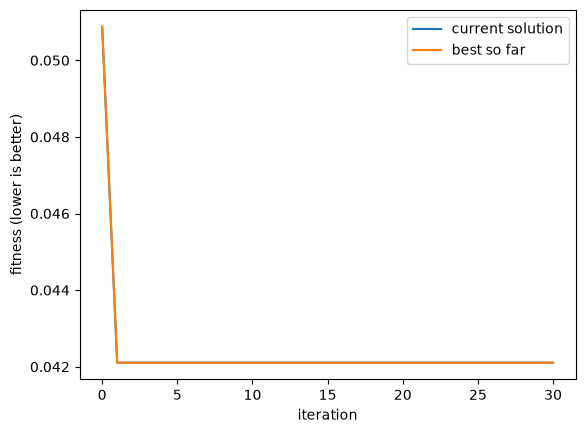

In [ ]:
best_s, best_f, hist, best_hist = tabu_search(fitness, s0, tenure=5, max_iter=30)

print("\nbest f:", round(best_f, 4), "| features kept:", best_s.sum())
print([feature_names[i] for i in np.where(best_s == 1)[0]])

plt.plot(hist, label="current solution")
plt.plot(best_hist, label="best so far")
plt.xlabel("iteration"); plt.ylabel("fitness (lower is better)"); plt.legend(); plt.show()

In [16]:
spam = fetch_ucirepo(id=94)
X_spam = spam.data.features
y_spam = spam.data.targets.squeeze()

df_spam = pd.concat([X_spam, y_spam.rename("target")], axis=1)


In [17]:
df_spam

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,target
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.000,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.000,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.010,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.000,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.000,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4596,0.31,0.00,0.62,0.0,0.00,0.31,0.00,0.00,0.00,0.00,...,0.000,0.232,0.0,0.000,0.000,0.000,1.142,3,88,0
4597,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.00,...,0.000,0.000,0.0,0.353,0.000,0.000,1.555,4,14,0
4598,0.30,0.00,0.30,0.0,0.00,0.00,0.00,0.00,0.00,0.00,...,0.102,0.718,0.0,0.000,0.000,0.000,1.404,6,118,0
4599,0.96,0.00,0.00,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.000,0.057,0.0,0.000,0.000,0.000,1.147,5,78,0
